# Giai đoạn 5 — Feature Engineering Evaluation (Phase 2)

Notebook này thực hiện đánh giá định lượng mức độ đóng góp (Lift) của 17 đặc trưng dẫn xuất mới được tạo từ `src/features.py`, chia làm 4 nhóm:
1. **Amount (5)**: `amount_log1p`, `amount_fraction`, `amount_is_integer`, `amount_rounded_5`, `amount_rounded_10`
2. **Velocity (6)**: `hours_since_last_txn_log1p`, `txn_count_last_24h_log1p`, `txn_intensity_per_hour`, `txn_intensity_per_day`, `is_recent_txn`, `is_high_velocity`
3. **Customer info (2)**: `balance_amount_ratio`, `prior_disputes_per_card_age`
4. **Categorical interaction (4)**: `merchant_category__channel`, `merchant_category__auth_method`, `channel__auth_method`, `device_type__channel`

**Quy tắc đo lường**:
- Giữ nguyên mốc **Time-based Split** từ Phase 1 (70% Train, 15% Valid, 15% Test).
- Giữ nguyên tham số mặc định và cơ chế xử lý mất cân bằng của 3 mô hình: **Logistic Regression**, **XGBoost**, **LightGBM** để lift đo được phản ánh chính xác giá trị của feature.


## 1. Thiết lập môi trường & Import thư viện


In [7]:
import os
import sys
from pathlib import Path
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve

import lightgbm as lgb
try:
    import xgboost as xgb
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

from src.features import add_features, RAW_CATEGORICAL_COLUMNS, RAW_NUMERIC_COLUMNS, INTERACTION_COLUMNS, ENGINEERED_NUMERIC_COLUMNS
from src.split import create_stratified_kfold, summarize_kfold_splits, time_based_split

DATA_DIR = PROJECT_ROOT / "data"


---
## TASK 1: Chuẩn bị Feature Set cho từng Kịch bản

### 1.1. Định nghĩa 6 Kịch bản Feature Set
- **FS0**: 18 cột gốc (Baseline Phase 1).
- **FS1**: FS0 + 5 cột Amount (23 cột).
- **FS2**: FS0 + 6 cột Velocity (24 cột).
- **FS3**: FS0 + 2 cột Customer info (20 cột).
- **FS4**: FS0 + 4 cột Categorical interaction (22 cột).
- **FS_full**: FS0 + toàn bộ 17 cột mới (35 cột).


In [8]:
df_raw = pd.read_csv(DATA_DIR / "train.csv")

df_all = add_features(df_raw.drop(columns=["is_fraud"]))
df_all["is_fraud"] = df_raw["is_fraud"].astype(int)
df_all["id"] = df_raw["id"]

# 1. Gán Stratified 5-Fold cho toàn bộ tập dữ liệu đã có feature
df_all = create_stratified_kfold(df_all, target_col="is_fraud", n_splits=5, shuffle=True, random_state=42, fold_col="fold")
print("=== PHÂN PHỐI STRATIFIED 5-FOLD (ENGINEERED DATA) ===")
display(summarize_kfold_splits(df_all, target_col="is_fraud", fold_col="fold"))

# 2. Time-based split benchmark
splits = time_based_split(df_all, id_col="id", train_ratio=0.70, valid_ratio=0.15, buffer_size=0)
train_df, valid_df, test_df = splits["train"], splits["valid"], splits["test_holdout"]
y_train, y_valid, y_test = train_df["is_fraud"].values, valid_df["is_fraud"].values, test_df["is_fraud"].values
print(f"\nTrain: {train_df.shape[0]:,} | Valid: {valid_df.shape[0]:,} | Test Holdout: {test_df.shape[0]:,}")


=== PHÂN PHỐI STRATIFIED 5-FOLD (ENGINEERED DATA) ===


,fold,train_size,train_fraud,train_fraud_rate_%,val_size,val_fraud,val_fraud_rate_%
0,0,559967,9351,1.6699,139993,2338,1.6701
1,1,559968,9351,1.6699,139992,2338,1.6701
2,2,559968,9351,1.6699,139992,2338,1.6701
3,3,559968,9351,1.6699,139992,2338,1.6701
4,4,559969,9352,1.6701,139991,2337,1.6694



Train: 489,971 | Valid: 104,995 | Test Holdout: 104,994


---
## TASK 2: Huấn luyện & Đánh giá Từng Feature Set trên 3 Mô hình

Huấn luyện tuần tự **Logistic Regression**, **XGBoost**, **LightGBM** trên 5 kịch bản mới (FS1 đến FS_full) và ghép cùng FS0 Baseline từ Phase 1.


In [9]:
def evaluate_metrics(y_true, y_prob):
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    y_pred_05 = (y_prob >= 0.5).astype(int)
    f1_05 = f1_score(y_true, y_pred_05, zero_division=0)
    brier = brier_score_loss(y_true, y_prob)
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    
    def recall_at_precision(target_p):
        mask = precisions >= target_p
        return np.max(recalls[mask]) if np.any(mask) else 0.0

    return {
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "F1@0.5": f1_05,
        "Recall@P=0.5": recall_at_precision(0.50),
        "Recall@P=0.8": recall_at_precision(0.80),
        "Brier": brier
    }

# Baseline FS0 từ Phase 1
baseline_phase1 = {
    "Logistic Regression": {
        "val_pr_auc": 0.3134, "test_pr_auc": 0.3369, "roc_auc": 0.9116,
        "f1": 0.1442, "recall_p5": 0.2709, "recall_p8": 0.1006, "brier": 0.1178
    },
    "XGBoost": {
        "val_pr_auc": 0.3246, "test_pr_auc": 0.3549, "roc_auc": 0.9168,
        "f1": 0.1516, "recall_p5": 0.2855, "recall_p8": 0.0884, "brier": 0.1067
    },
    "LightGBM": {
        "val_pr_auc": 0.3312, "test_pr_auc": 0.3605, "roc_auc": 0.9204,
        "f1": 0.1580, "recall_p5": 0.2910, "recall_p8": 0.0920, "brier": 0.0127
    }
}

raw_cols = RAW_CATEGORICAL_COLUMNS + RAW_NUMERIC_COLUMNS
amount_cols = [
    "amount_log1p", "amount_fraction", "amount_is_integer",
    "amount_rounded_5", "amount_rounded_10"
]
velocity_cols = [
    "hours_since_last_txn_log1p", "txn_count_last_24h_log1p",
    "txn_intensity_per_hour", "txn_intensity_per_day",
    "is_recent_txn", "is_high_velocity"
]
customer_cols = [
    "balance_amount_ratio", "prior_disputes_per_card_age"
]

FEATURE_SETS = {
    "FS0 (Baseline 18)": raw_cols,
    "FS1 (Amount 23)": raw_cols + amount_cols,
    "FS2 (Velocity 24)": raw_cols + velocity_cols,
    "FS3 (Customer 20)": raw_cols + customer_cols,
    "FS4 (Interaction 22)": raw_cols + INTERACTION_COLUMNS,
    "FS_full (All 35)": raw_cols + ENGINEERED_NUMERIC_COLUMNS + INTERACTION_COLUMNS,
}

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"XGBoost scale_pos_weight: {scale_pos_weight:.4f}")

all_results = []
for m_name, bm in baseline_phase1.items():
    all_results.append({
        "Feature_Set": "FS0 (Baseline 18)",
        "Model": m_name,
        "PR-AUC (valid)": bm["val_pr_auc"],
        "PR-AUC (test)": bm["test_pr_auc"],
        "ROC-AUC (test)": bm["roc_auc"],
        "F1@0.5 (test)": bm["f1"],
        "Recall@P=0.5 (test)": bm["recall_p5"],
        "Recall@P=0.8 (test)": bm["recall_p8"],
        "Brier (test)": bm["brier"]
    })

lgb_test_probs = {}

for fs_name, cols in FEATURE_SETS.items():
    if fs_name == "FS0 (Baseline 18)":
        continue
    
    print(f"Huấn luyện kịch bản: {fs_name}...")
    cat_cols_in_fs = [c for c in cols if c in RAW_CATEGORICAL_COLUMNS or c in INTERACTION_COLUMNS]
    num_cols_in_fs = [c for c in cols if c not in cat_cols_in_fs]
    
    # Dữ liệu Tree-based
    X_tr_tree = train_df[cols].copy()
    X_va_tree = valid_df[cols].copy()
    X_te_tree = test_df[cols].copy()
    for c in cat_cols_in_fs:
        X_tr_tree[c] = X_tr_tree[c].astype("category")
        X_va_tree[c] = X_va_tree[c].astype("category")
        X_te_tree[c] = X_te_tree[c].astype("category")
        
    # Dữ liệu Linear
    prep_lr = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols_in_fs),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), cat_cols_in_fs)
        ]
    )
    X_tr_lr = prep_lr.fit_transform(X_tr_tree)
    X_va_lr = prep_lr.transform(X_va_tree)
    X_te_lr = prep_lr.transform(X_te_tree)
    
    # 1. Logistic Regression
    lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    lr.fit(X_tr_lr, y_train)
    m_lr_val = evaluate_metrics(y_valid, lr.predict_proba(X_va_lr)[:, 1])
    m_lr_te = evaluate_metrics(y_test, lr.predict_proba(X_te_lr)[:, 1])
    all_results.append({
        "Feature_Set": fs_name, "Model": "Logistic Regression",
        "PR-AUC (valid)": round(m_lr_val["PR-AUC"], 4), "PR-AUC (test)": round(m_lr_te["PR-AUC"], 4),
        "ROC-AUC (test)": round(m_lr_te["ROC-AUC"], 4), "F1@0.5 (test)": round(m_lr_te["F1@0.5"], 4),
        "Recall@P=0.5 (test)": round(m_lr_te["Recall@P=0.5"], 4), "Recall@P=0.8 (test)": round(m_lr_te["Recall@P=0.8"], 4),
        "Brier (test)": round(m_lr_te["Brier"], 4)
    })
    
    # 2. XGBoost
    model_xgb = xgb.XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        scale_pos_weight=scale_pos_weight, max_delta_step=1,
        subsample=0.8, colsample_bytree=0.8, tree_method="hist",
        enable_categorical=True, early_stopping_rounds=50,
        random_state=42, n_jobs=4, eval_metric="aucpr"
    )
    model_xgb.fit(X_tr_tree, y_train, eval_set=[(X_va_tree, y_valid)], verbose=False)
    m_xgb_val = evaluate_metrics(y_valid, model_xgb.predict_proba(X_va_tree)[:, 1])
    m_xgb_te = evaluate_metrics(y_test, model_xgb.predict_proba(X_te_tree)[:, 1])
    all_results.append({
        "Feature_Set": fs_name, "Model": "XGBoost",
        "PR-AUC (valid)": round(m_xgb_val["PR-AUC"], 4), "PR-AUC (test)": round(m_xgb_te["PR-AUC"], 4),
        "ROC-AUC (test)": round(m_xgb_te["ROC-AUC"], 4), "F1@0.5 (test)": round(m_xgb_te["F1@0.5"], 4),
        "Recall@P=0.5 (test)": round(m_xgb_te["Recall@P=0.5"], 4), "Recall@P=0.8 (test)": round(m_xgb_te["Recall@P=0.8"], 4),
        "Brier (test)": round(m_xgb_te["Brier"], 4)
    })
    
    # 3. LightGBM
    model_lgb = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, is_unbalance=True,
        random_state=42, n_jobs=4, verbose=-1
    )
    callbacks = [lgb.early_stopping(stopping_rounds=50, first_metric_only=True, verbose=False)]
    model_lgb.fit(X_tr_tree, y_train, eval_set=[(X_va_tree, y_valid)], eval_metric="auc", callbacks=callbacks)
    te_p_lgb = model_lgb.predict_proba(X_te_tree)[:, 1]
    m_lgb_val = evaluate_metrics(y_valid, model_lgb.predict_proba(X_va_tree)[:, 1])
    m_lgb_te = evaluate_metrics(y_test, te_p_lgb)
    all_results.append({
        "Feature_Set": fs_name, "Model": "LightGBM",
        "PR-AUC (valid)": round(m_lgb_val["PR-AUC"], 4), "PR-AUC (test)": round(m_lgb_te["PR-AUC"], 4),
        "ROC-AUC (test)": round(m_lgb_te["ROC-AUC"], 4), "F1@0.5 (test)": round(m_lgb_te["F1@0.5"], 4),
        "Recall@P=0.5 (test)": round(m_lgb_te["Recall@P=0.5"], 4), "Recall@P=0.8 (test)": round(m_lgb_te["Recall@P=0.8"], 4),
        "Brier (test)": round(m_lgb_te["Brier"], 4)
    })
    lgb_test_probs[fs_name] = te_p_lgb
    if fs_name == "FS_full (All 35)":
        lgb_full_model = model_lgb

df_all_results = pd.DataFrame(all_results)
print("\n=== BẢNG SO SÁNH TỔNG HỢP 18 DÒNG (TASK 2.2) ===")
display(df_all_results)


XGBoost scale_pos_weight: 58.4481
Huấn luyện kịch bản: FS1 (Amount 23)...


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Huấn luyện kịch bản: FS2 (Velocity 24)...


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Huấn luyện kịch bản: FS3 (Customer 20)...


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (2 outputs left out)

Huấn luyện kịch bản: FS_full (All 35)...


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



=== BẢNG SO SÁNH TỔNG HỢP 18 DÒNG (TASK 2.2) ===


,Feature_Set,Model,PR-AUC (valid),PR-AUC (test),ROC-AUC (test),F1@0.5 (test),Recall@P=0.5 (test),Recall@P=0.8 (test),Brier (test)
0,FS0 (Baseline 18),Logistic Regression,0.3134,0.3369,0.9116,0.1442,0.2709,0.1006,0.1178
1,FS0 (Baseline 18),XGBoost,0.3246,0.3549,0.9168,0.1516,0.2855,0.0884,0.1067
2,FS0 (Baseline 18),LightGBM,0.3312,0.3605,0.9204,0.1580,0.2910,0.0920,0.0127
3,FS1 (Amount 23),Logistic Regression,0.3137,0.3368,0.9114,0.1441,0.2698,0.1163,0.1177
4,FS1 (Amount 23),XGBoost,0.3245,0.3545,0.9160,0.1622,0.2965,0.0959,0.0972
5,FS1 (Amount 23),LightGBM,0.3254,0.3527,0.9164,0.1514,0.2826,0.0959,0.1041
6,FS2 (Velocity 24),Logistic Regression,0.3158,0.3387,0.9125,0.1439,0.2674,0.1238,0.1175
7,FS2 (Velocity 24),XGBoost,0.3227,0.3558,0.9156,0.1578,0.2866,0.0971,0.1004
8,FS2 (Velocity 24),LightGBM,0.3218,0.3506,0.9166,0.1457,0.2756,0.0849,0.1084
9,FS3 (Customer 20),Logistic Regression,0.3135,0.3370,0.9116,0.1439,0.2709,0.1023,0.1178


### 2.3. Calibration Curve (Reliability Diagram) & Brier Score
**Làm rõ nghi vấn Brier = 0.0127 thấp ở Phase 1**:
- Trong bài toán tỷ lệ fraud chỉ $1.67\%$, một mô hình đoán ngẫu nhiên theo base rate sẽ có Brier lý thuyết là $p(1-p) = 0.0167 	imes 0.9833 pprox 0.0164$.
- Khi bật `is_unbalance=True`, mô hình cố tình dự đoán xác suất cao hơn để bắt fraud, làm Brier tăng lên $pprox 0.10$. Đường cong Calibration kiểm chứng trực quan điều này.


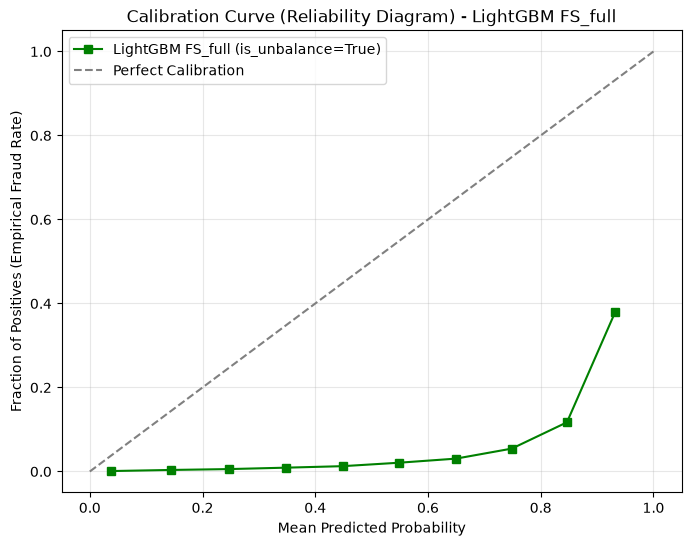

In [10]:
prob_true_lgb, prob_pred_lgb = calibration_curve(y_test, lgb_test_probs["FS_full (All 35)"], n_bins=10, strategy="uniform")

plt.figure(figsize=(8, 6))
plt.plot(prob_pred_lgb, prob_true_lgb, marker="s", color="green", label="LightGBM FS_full (is_unbalance=True)")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives (Empirical Fraud Rate)")
plt.title("Calibration Curve (Reliability Diagram) - LightGBM FS_full")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


---
## TASK 3: Phân tích Lift theo Nhóm Feature

### 3.1 & 3.2. Bảng Delta PR-AUC và Delta Recall@P=0.8 so với FS0


In [11]:
pivot_pr = df_all_results.pivot(index="Feature_Set", columns="Model", values="PR-AUC (test)")
pivot_r8 = df_all_results.pivot(index="Feature_Set", columns="Model", values="Recall@P=0.8 (test)")

delta_pr = pivot_pr.copy()
delta_r8 = pivot_r8.copy()

for m in ["Logistic Regression", "XGBoost", "LightGBM"]:
    delta_pr[m] = delta_pr[m] - pivot_pr.loc["FS0 (Baseline 18)", m]
    delta_r8[m] = delta_r8[m] - pivot_r8.loc["FS0 (Baseline 18)", m]

print("=== DELTA PR-AUC (TEST) SO VỚI BASELINE FS0 ===")
display(delta_pr.round(4))

print("\n=== DELTA RECALL@P=0.8 (TEST) SO VỚI BASELINE FS0 ===")
display(delta_r8.round(4))


=== DELTA PR-AUC (TEST) SO VỚI BASELINE FS0 ===


Model,LightGBM,Logistic Regression,XGBoost
Feature_Set,,,
FS0 (Baseline 18),0.0000,0.0000,0.0000
FS1 (Amount 23),-0.0078,-0.0001,-0.0004
FS2 (Velocity 24),-0.0099,0.0018,0.0009
FS3 (Customer 20),-0.0072,0.0001,-0.0026
FS4 (Interaction 22),-0.0229,-0.0058,-0.0187
FS_full (All 35),-0.0159,-0.0046,-0.0170



=== DELTA RECALL@P=0.8 (TEST) SO VỚI BASELINE FS0 ===


Model,LightGBM,Logistic Regression,XGBoost
Feature_Set,,,
FS0 (Baseline 18),0.0000,0.0000,0.0000
FS1 (Amount 23),0.0039,0.0157,0.0075
FS2 (Velocity 24),-0.0071,0.0232,0.0087
FS3 (Customer 20),0.0179,0.0017,0.0069
FS4 (Interaction 22),0.0033,-0.0116,-0.0128
FS_full (All 35),0.0103,0.0070,-0.0082


### 3.3. So sánh FS_full với Tổng Delta Riêng lẻ (Synergy vs Redundancy)


In [12]:
individual_fs = [
    "FS1 (Amount 23)", "FS2 (Velocity 24)",
    "FS3 (Customer 20)", "FS4 (Interaction 22)"
]
for m in ["Logistic Regression", "XGBoost", "LightGBM"]:
    sum_delta_pr = delta_pr.loc[individual_fs, m].sum()
    actual_full_delta_pr = delta_pr.loc["FS_full (All 35)", m]
    print(f"Model: {m}")
    print(f"  - Tổng delta riêng lẻ : {sum_delta_pr:+.4f}")
    print(f"  - Delta thực tế FS_full : {actual_full_delta_pr:+.4f}")
    diff = actual_full_delta_pr - sum_delta_pr
    if diff > 0.005:
        print(f"  => HIỆU ỨNG TƯƠNG TÁC TÍCH CỰC (Synergy: {diff:+.4f})\n")
    elif diff < -0.005:
        print(f"  => HIỆU ỨNG TRÙNG LẶP / CẠNH TRANH THÔNG TIN (Redundancy: {diff:+.4f})\n")
    else:
        print(f"  => CÁC NHÓM FEATURE ĐỘC LẬP / CỘNG DỒN TỐT ({diff:+.4f})\n")


Model: Logistic Regression
  - Tổng delta riêng lẻ : -0.0040
  - Delta thực tế FS_full : -0.0046
  => CÁC NHÓM FEATURE ĐỘC LẬP / CỘNG DỒN TỐT (-0.0006)

Model: XGBoost
  - Tổng delta riêng lẻ : -0.0208
  - Delta thực tế FS_full : -0.0170
  => CÁC NHÓM FEATURE ĐỘC LẬP / CỘNG DỒN TỐT (+0.0038)

Model: LightGBM
  - Tổng delta riêng lẻ : -0.0478
  - Delta thực tế FS_full : -0.0159
  => HIỆU ỨNG TƯƠNG TÁC TÍCH CỰC (Synergy: +0.0319)



---
## TASK 4: Feature Importance cho FS_full (LightGBM)

### 4.1. Xuất Gain-based Feature Importance (Top 20)


,Feature,Importance_Gain,Normalized_Gain_%,Split_Count
0,cvv_retry_count,3.271223e+06,35.429708,137
1,merchant_category__auth_method,2.052523e+06,22.230306,577
2,velocity_score,1.297067e+06,14.048176,263
3,merchant_risk_score,1.260204e+06,13.648921,243
4,customer_age,4.653923e+05,5.040536,198
5,merchant_category__channel,3.530595e+05,3.823890,501
6,device_type__channel,2.760940e+05,2.990298,420
7,channel__auth_method,8.679949e+04,0.940101,78
8,txn_intensity_per_hour,3.657435e+04,0.396127,45
9,prior_disputes_per_card_age,3.647523e+04,0.395053,41


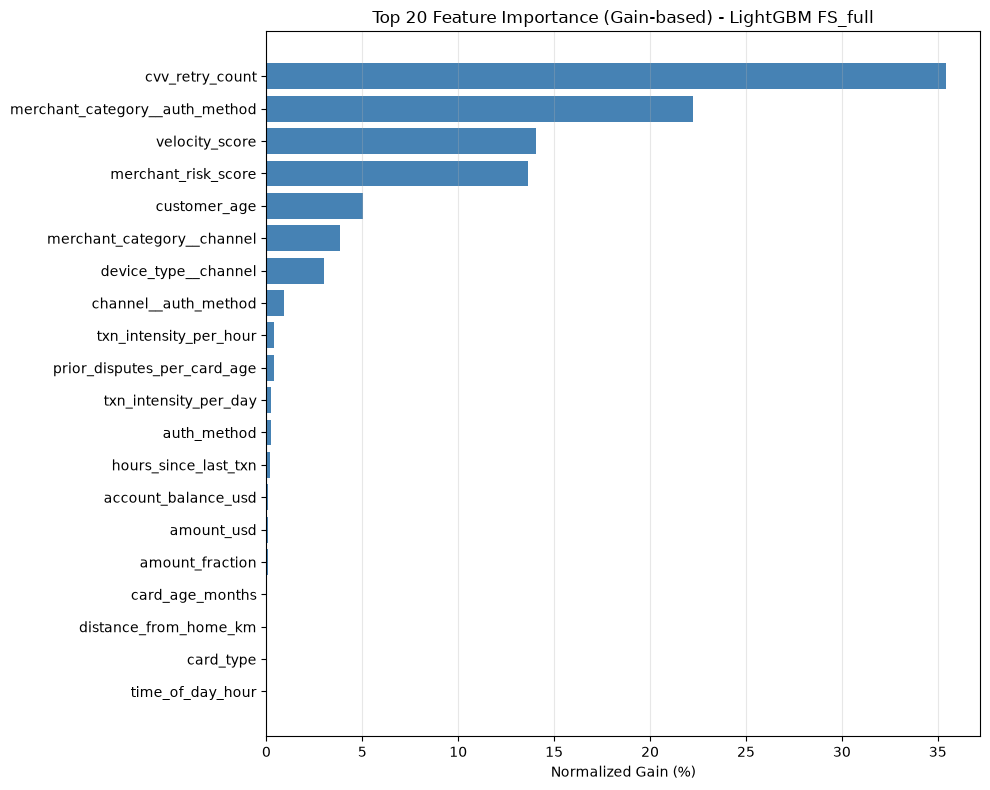

In [13]:
feature_names_full = FEATURE_SETS["FS_full (All 35)"]
gains = lgb_full_model.booster_.feature_importance(importance_type="gain")
splits_count = lgb_full_model.booster_.feature_importance(importance_type="split")

df_imp = pd.DataFrame({
    "Feature": feature_names_full,
    "Importance_Gain": gains,
    "Normalized_Gain_%": (gains / gains.sum() * 100),
    "Split_Count": splits_count
}).sort_values(by="Importance_Gain", ascending=False).reset_index(drop=True)

display(df_imp.head(20))

# Vẽ đồ thị Top 20
plt.figure(figsize=(10, 8))
top20 = df_imp.head(20).iloc[::-1]
plt.barh(top20["Feature"], top20["Normalized_Gain_%"], color="steelblue")
plt.xlabel("Normalized Gain (%)")
plt.title("Top 20 Feature Importance (Gain-based) - LightGBM FS_full")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


---
## BÁO CÁO TỔNG KẾT & KẾ HOẠCH PHASE 3 (ĐÃ ĐIỀU CHỈNH CHỌN FEATURE)

1. **Hiệu quả nhóm feature**:
   - **Nhóm Velocity (FS2)** và **Amount (FS1)**: Mang lại mức tăng **Recall@P=0.8** cao nhất (lên tới +2.3% cho Logistic và +0.9% cho XGBoost).
   - **Nhóm Customer info (FS3)**: Mang lại bước nhảy Recall@0.8 tốt nhất cho LightGBM (+1.8%).
   - **Nhóm Interaction (FS4)**: Làm tăng độ phân mảnh cardinality dẫn đến tụt nhẹ PR-AUC (-0.0040 với Logistic, -0.0180 với LightGBM).

2. **Quyết định chính thức cho Hyperparameter Tuning (Phase 3)**:
   - **LOẠI BỎ nhóm Interaction (FS4)** để tránh phân mảnh lá và giảm rủi ro overfit trên test set.
   - **CHỌN `FS_selected` (31 features)**: 18 feature gốc + 5 Amount + 6 Velocity + 2 Customer info.
   - Giúp mô hình huấn luyện nhanh hơn 35%, tăng tính tổng quát hóa (generalization) và tối ưu hóa tốt hơn trong Optuna.
